# EMBERFALL — คู่มือและเกม Python ที่กดรันได้
**ผู้จัดทำ: ศิริโรจน์ นามศรีอุ่น**  
**รหัสนิสิต: 69540047**

## 1. แนวคิดและวัตถุประสงค์
เกมผจญภัยแบบเลือกคำสั่ง ผ่าน 3 ดินแดน ปราบศัตรู 6 ตัวและบอส 3 ตัว ผู้เล่นต้องจัดการ HP พลังสกิล เงินและยา เพื่อฝึก Conditions, Loops, Functions, Lists และ Dictionaries

## 2. วิธีใช้สมุดบันทึก
1. เปิดใน Jupyter หรือ Google Colab แล้วกด **Run all / เรียกใช้ทั้งหมด**
2. รอเซลล์ทดสอบและการสร้างหน้าจอเสร็จ ไม่มีเซลล์ `input()` ที่ต้องรอคำตอบ
3. ไปหัวข้อ **7. เล่นเกมใน Notebook** เลือกอาชีพ แล้วคลิกปุ่มเล่น
4. หน้าจอมีรูปฉาก ตัวละคร บอส และแอนิเมชัน CSS แบบสั้น กติกาทั้งหมดคำนวณด้วย Python ใน kernel
5. ปุ่ม **เริ่มใหม่ / เลือกอาชีพ** กลับหน้าเลือกตัวละคร กด **จบเกม** เพื่อปิดส่วนเล่นเกม
6. ปิด notebook หรือ restart kernel แล้วความคืบหน้าจะหาย

**ไม่ต้องแตก ZIP หรืออัปโหลดรูป/ไฟล์ Python เพิ่ม** โค้ดและรูปอยู่ครบในสมุดบันทึกนี้ ต้องมี IPython และ ipywidgets (ติดตั้งไว้ใน Google Colab/Jupyter ส่วนใหญ่) หากเซลล์แจ้งไม่มี ipywidgets ให้รัน `%pip install ipywidgets` แล้ว restart kernel และ Run all อีกครั้ง

> เวอร์ชัน Notebook ใช้ widget ของ Jupyter ส่วนไฟล์ Pygame และเว็บไซต์ใน ZIP ยังคงเปิดผ่าน `.bat` ได้ตามเดิม อย่าใช้ GitHub preview เพื่อเล่น เพราะ GitHub แสดงไฟล์ได้แต่ไม่ได้รัน Python kernel

## 3. Flowchart

Flowchart

เมนู UI เรียก `Game.command()` → ตรวจเงื่อนไข → อัปเดตสถานะ → ตรวจชนะ/แพ้ → วาดหน้าจอใหม่ คำสั่งใช้ไม่ได้ไม่เสียเทิร์น

## 4. ฟังก์ชัน Python พื้นฐาน (Code cell)
โค้ดนี้มีสูตรต่อสู้ การสร้างตัวละคร ศัตรู ฟื้นพลัง ซื้อยา และตีบวก โดยแยกการรับคำสั่งออกจากการประมวลผล เซลล์นี้นิยามฟังก์ชันเท่านั้น ไม่เปิดเกมข้อความเอง

In [1]:
"""EMBERFALL - เกม Python มาตรฐาน ไม่ต้องติดตั้งแพ็กเกจเพิ่ม
รัน: python emberfall.py | ปิดแอนิเมชัน: python emberfall.py --fast
"""
import random
import sys
import time

ANIMATION = True
CLASSES = {
    '1': dict(name='อัศวิน', hp=145, atk=19, skill='ดาบพิพากษา'),
    '2': dict(name='จอมเวท', hp=105, atk=25, skill='ดาวตกเพลิง'),
    '3': dict(name='นักธนู', hp=120, atk=22, skill='ศรทะลวง'),
}
REGIONS = [
    dict(name='ป่ากระซิบ', enemy='หมาป่าเงา', boss='ผู้พิทักษ์รากไม้'),
    dict(name='วิหารจันทรา', enemy='ผู้เฝ้าวิหาร', boss='อัศวินจันทราทมิฬ'),
    dict(name='ยอดเขาเถ้าถ่าน', enemy='อสูรเถ้าถ่าน', boss='มังกรราชันเถ้าถ่าน'),
]

class ExitGame(Exception):
    """ส่งสัญญาณออกจากเกมกลับไปยัง main โดยไม่แสดง traceback"""


def type_text(text, speed=0.012):
    if not ANIMATION:
        print(text)
        return
    for char in text:
        print(char, end='', flush=True)
        time.sleep(speed)
    print()


def loading(text):
    print(text, end='', flush=True)
    for _ in range(3):
        if ANIMATION:
            time.sleep(0.18)
        print(' .', end='', flush=True)
    print()


def attack_animation(name, damage, skill=False):
    type_text(f"{'✦' if skill else '⚔'} {name} {'รวบรวมพลัง' if skill else 'พุ่งเข้าโจมตี'}...")
    print(f"      {'✧ ━━━ ✦ ━━━ ✧' if skill else '─── ⚔ ──→'}  −{damage} HP")
    if ANIMATION:
        time.sleep(0.18)


def choose(prompt, options):
    while True:
        answer = input(prompt).strip()
        if answer.lower() in ('0', 'q', 'quit'):
            raise ExitGame()
        if answer in options:
            return answer
        print('ข้อมูลไม่ถูกต้อง เลือก ' + ', '.join(options) + ' หรือ 0 เพื่อออก')


def create_player(class_key, name='ผู้ถือเปลวไฟ'):
    job = CLASSES[class_key]
    return dict(name=name, job=job['name'], hp=job['hp'], max_hp=job['hp'],
                atk=job['atk'], skill=job['skill'], gold=30, potions=3,
                energy=2, upgrades=0, wins=0)


def heal(player, amount):
    before = player['hp']
    player['hp'] = min(player['max_hp'], before + amount)
    return player['hp'] - before


def show_status(p):
    blocks = round(20 * p['hp'] / p['max_hp'])
    print(f"\n{p['name']} | {p['job']}")
    print(f"HP [{'█' * blocks}{'░' * (20-blocks)}] {p['hp']}/{p['max_hp']}")
    print(f"ATK {p['atk']} | พลังสกิล {'◆' * p['energy']}{'◇' * (3-p['energy'])}")
    print(f"เหรียญ {p['gold']} | ยาฟื้นพลัง {p['potions']}/5")


def create_enemy(region_index, is_boss):
    region = REGIONS[region_index]
    hp = 125 + region_index * 75 if is_boss else 48 + region_index * 27
    return dict(name=region['boss'] if is_boss else region['enemy'],
                hp=hp, max_hp=hp, atk=17+region_index*7 if is_boss else 9+region_index*5,
                boss=is_boss)


def combat_turn(p, enemy, action, turn, rng):
    """หนึ่งเทิร์น: ตรวจคำสั่งก่อนแก้ข้อมูล และไม่ให้ศัตรูที่ตายแล้วโจมตีกลับ"""
    if action not in ('1', '2', '3', '4'):
        raise ValueError('คำสั่งไม่ถูกต้อง')
    if p['hp'] <= 0 or enemy['hp'] <= 0:
        raise ValueError('การต่อสู้นี้จบแล้ว')
    if action == '2' and p['energy'] < 2:
        raise ValueError('พลังสกิลไม่พอ ต้องมีอย่างน้อย 2')
    if action == '4' and (p['potions'] == 0 or p['hp'] == p['max_hp']):
        raise ValueError('ยาหมดแล้ว' if p['potions'] == 0 else 'พลังชีวิตเต็มอยู่')
    result = dict(damage=0, received=0, healed=0, heavy=turn % 3 == 0,
                  guarded=action == '3', won=False)
    if action in ('1', '2'):
        multiplier = 2.2 if action == '2' else 1
        result['damage'] = round(p['atk'] * multiplier * rng.uniform(0.92, 1.08))
        enemy['hp'] = max(0, enemy['hp'] - result['damage'])
        p['energy'] = p['energy'] - 2 if action == '2' else min(3, p['energy'] + 1)
    elif action == '3':
        p['energy'] = min(3, p['energy'] + 1)
    else:
        p['potions'] -= 1
        result['healed'] = heal(p, 55)
    if enemy['hp'] == 0:
        result['won'] = True
        return result
    result['received'] = round(enemy['atk'] * (2.5 if result['heavy'] else 1)
                               * (0.25 if result['guarded'] else 1))
    p['hp'] = max(0, p['hp'] - result['received'])
    return result


def award_victory(p, enemy):
    reward = 55 if enemy['boss'] else 25
    p['gold'] += reward
    p['wins'] += 1
    p['energy'] = min(3, p['energy'] + 1)
    return reward


def battle(p, enemy, rng):
    p['energy'] = min(3, p['energy'] + 1)
    turn = 1
    type_text(f"\nพบ {enemy['name']}! {'[ BOSS ]' if enemy['boss'] else ''}")
    while p['hp'] > 0 and enemy['hp'] > 0:
        show_status(p)
        print(f"\n{enemy['name']} HP {enemy['hp']}/{enemy['max_hp']} | เทิร์น {turn}")
        print('⚠ เตรียมท่าไม้ตาย! แนะนำตั้งรับ' if turn % 3 == 0 else '◇ ศัตรูเตรียมโจมตีปกติ')
        print(f"1 โจมตี (+1 พลัง) | 2 {p['skill']} (ใช้ 2 พลัง)")
        print('3 ตั้งรับ (ลดดาเมจ 75%, +1 พลัง) | 4 ดื่มยา (+55 HP, เสียเทิร์น)')
        action = choose('เลือก 1–4 | 0 ออก: ', ['1', '2', '3', '4'])
        try:
            result = combat_turn(p, enemy, action, turn, rng)
        except ValueError as error:
            print(error)
            continue  # คำสั่งใช้ไม่ได้ไม่เสียเทิร์น
        if result['damage']:
            attack_animation(p['skill'] if action == '2' else p['name'], result['damage'], action == '2')
        elif result['guarded']:
            type_text('◈ คุณยกโล่ตั้งรับอย่างมั่นคง')
        else:
            type_text(f"✚ ดื่มยา ฟื้น {result['healed']} HP")
        if result['won']:
            reward = award_victory(p, enemy)
            type_text(f"ชนะ {enemy['name']}! ได้รับ {reward} เหรียญ")
            return True
        print(f"{'ท่าไม้ตาย!' if result['heavy'] else 'ศัตรูโจมตีกลับ!'} −{result['received']} HP")
        turn += 1
    return False


def explore(p, rng):
    print('\nทางแยก: 1 ลำธาร (+10 HP) | 2 ล่าสมบัติ (+18 เหรียญ, เสีย 5–11 HP)')
    action = choose('เลือกเส้นทาง | 0 ออก: ', ['1', '2'])
    loading('กำลังเดินทาง')
    if action == '1':
        print(f"พักริมลำธาร ฟื้น {heal(p, 10)} HP")
    else:
        damage = min(rng.randint(5, 11), p['hp'] - 1)
        p['hp'] -= damage
        p['gold'] += 18
        print(f'พบสมบัติ +18 เหรียญ แต่ติดกับดัก −{damage} HP')


def upgrade(p):
    cost = 35 + p['upgrades'] * 15
    if p['gold'] < cost:
        raise ValueError('เหรียญไม่พอ')
    p['gold'] -= cost
    p['atk'] += 5
    p['upgrades'] += 1
    return cost


def buy_potion(p):
    if p['potions'] >= 5:
        raise ValueError('ถือยาได้สูงสุด 5 ขวด')
    if p['gold'] < 20:
        raise ValueError('เหรียญไม่พอ')
    p['gold'] -= 20
    p['potions'] += 1


def camp(p):
    type_text('\nกองไฟของผู้เดินทางกำลังส่องแสง...')
    while True:
        show_status(p)
        print(f"1 ตีบวก ATK +5 ({35+p['upgrades']*15} เหรียญ)")
        print('2 ซื้อยา (20 เหรียญ) | 3 พักฟื้นและเดินทางต่อ | 0 ออก')
        action = choose('เลือก: ', ['1', '2', '3'])
        try:
            if action == '1':
                print(f'ตีบวกสำเร็จ! ใช้ {upgrade(p)} เหรียญ')
            elif action == '2':
                buy_potion(p)
                print('ได้รับยา 1 ขวด')
            else:
                recovered = heal(p, round(p['max_hp'] * 0.32))
                p['energy'] = 3
                print(f'พักฟื้น {recovered} HP และเติมพลังสกิลเต็ม')
                return
        except ValueError as error:
            print(error)


def show_ending(p, won):
    print('\n' + '=' * 44)
    loading('ม่านเถ้าถ่านกำลังสลาย' if won else 'เปลวไฟกำลังริบหรี่')
    if won:
        type_text('มังกรราชันเถ้าถ่านล้มลง แสงสว่างกลับคืนสู่โลก')
        type_text('ตอนจบ: ผู้พิทักษ์เปลวไฟ')
        type_text('คุณกลับมาพร้อมความหวัง' if p['hp'] >= p['max_hp']*.5 else 'แม้บอบช้ำ คุณก็ไม่ปล่อยให้เปลวไฟดับลง')
    else:
        type_text('คุณล้มลง แต่ประกายไฟเล็ก ๆ ยังคงลอยอยู่')
        type_text('ตอนจบ: ประกายไฟที่ยังไม่ดับ')
        type_text('การเดินทางครั้งใหม่ยังรอคุณอยู่')
    show_status(p)
    print(f"ปราบศัตรู {p['wins']}/9 | ตีบวก {p['upgrades']} ครั้ง")
    print('=' * 44)


def play():
    for key, job in CLASSES.items():
        print(f"{key} {job['name']} | HP {job['hp']} / ATK {job['atk']}")
    key = choose('เลือกอาชีพ | 0 ออก: ', CLASSES)
    name = input('ชื่อตัวละคร (Enter ใช้ชื่อเริ่มต้น / 0 ออก): ').strip()
    if name == '0':
        raise ExitGame()
    p = create_player(key, name or 'ผู้ถือเปลวไฟ')
    rng = random.Random()
    type_text(f"\nการเดินทางของ {p['name']} เริ่มต้นขึ้น...")
    for region_index, region in enumerate(REGIONS):
        loading(f"\nเข้าสู่ {region['name']}")
        for encounter in range(3):
            boss = encounter == 2
            if boss:
                type_text(f"⚠ ประตูบอสอยู่ตรงหน้า: {region['boss']}")
            explore(p, rng)
            enemy = create_enemy(region_index, boss)
            if not battle(p, enemy, rng):
                show_ending(p, False)
                return
            if not (region_index == 2 and boss):
                camp(p)
    show_ending(p, True)


def main():
    global ANIMATION
    if '--fast' in sys.argv:
        ANIMATION = False
    print('EMBERFALL — ผู้พิทักษ์เปลวไฟ')
    print('พิมพ์ 0 ในเมนูเพื่อออก | เกมนี้ไม่บันทึกเมื่อปิดโปรแกรม')
    try:
        while True:
            print('\n1 เริ่มเกม | 2 เปิด/ปิดแอนิเมชัน | 0 จบโปรแกรม')
            option = choose('เลือก: ', ['1', '2'])
            if option == '2':
                ANIMATION = not ANIMATION
                print('แอนิเมชัน: ' + ('เปิด' if ANIMATION else 'ปิด'))
            else:
                play()
                print('\nกลับสู่เมนูหลักแล้ว เลือก 1 เพื่อเล่นใหม่ หรือ 0 เพื่อจบเกม')
    except (ExitGame, KeyboardInterrupt, EOFError):
        print()
        type_text('เปลวไฟจะรอคุณอยู่เสมอ...')
        print('จบเกมแล้ว ขอบคุณที่เล่นครับ')



# ปิด animation ของ console; UI ด้านล่างใช้ animation ของตัวเอง
ANIMATION = False

### ตัวควบคุมสถานะเกม
`if/elif` แยกหน้าสำรวจ ต่อสู้ กองไฟ และจบเกม แต่ละรูปแบบหน้าจอเรียกคลาสนี้ร่วมกัน

In [2]:
"""กติกา Python ร่วมกันระหว่างเกม Pygame และเว็บไซต์"""
import random
from types import SimpleNamespace
# ผูกกับฟังก์ชันใน Code cell ก่อนหน้า จึงไม่ต้อง import ไฟล์ภายนอก
core = SimpleNamespace(CLASSES=CLASSES, REGIONS=REGIONS,
    create_player=create_player, heal=heal, create_enemy=create_enemy,
    combat_turn=combat_turn, award_victory=award_victory,
    upgrade=upgrade, buy_potion=buy_potion)

class Game:
    def __init__(self, job='1', seed=None):
        if job not in core.CLASSES:
            raise ValueError('อาชีพไม่ถูกต้อง')
        self.player=core.create_player(job)
        self.job=job; self.rng=random.Random(seed)
        self.region=0; self.stage=0; self.turn=1
        self.mode='route'; self.enemy=None
        self.logs=['เลือกเส้นทางเพื่อเริ่มการผจญภัย']
        self.effect=None

    def snapshot(self):
        return dict(player=self.player.copy(),job=self.job,region=self.region,stage=self.stage,
                    turn=self.turn,mode=self.mode,enemy=self.enemy.copy() if self.enemy else None,
                    logs=list(self.logs[-6:]),effect=self.effect,
                    region_name=core.REGIONS[self.region]['name'])

    def command(self, action):
        self.effect=None
        p=self.player
        if self.mode=='route':
            if action not in ('safe','treasure'):raise ValueError('เลือกเส้นทางก่อน')
            if action=='safe':self.logs.append(f'พักริมธาร ฟื้น {core.heal(p,10)} HP')
            else:
                d=min(self.rng.randint(5,11),p['hp']-1);p['hp']-=d;p['gold']+=18
                self.logs.append(f'พบสมบัติ +18 เหรียญ กับดัก −{d} HP')
            self.enemy=core.create_enemy(self.region,self.stage==2)
            self.turn=1;p['energy']=min(3,p['energy']+1);self.mode='battle'
            self.logs.append('พบ '+self.enemy['name'])
        elif self.mode=='battle':
            mapping={'attack':'1','skill':'2','guard':'3','potion':'4'}
            if action not in mapping:raise ValueError('คำสั่งต่อสู้ไม่ถูกต้อง')
            result=core.combat_turn(p,self.enemy,mapping[action],self.turn,self.rng)
            self.effect=dict(action=action,**result)
            self.logs.append(f"{'สกิล' if action=='skill' else 'โจมตี' if action=='attack' else 'ตั้งรับ' if action=='guard' else 'ดื่มยา'}: ทำดาเมจ {result['damage']} / ฟื้น {result['healed']} / รับ {result['received']}")
            if result['won']:
                reward=core.award_victory(p,self.enemy);self.stage+=1
                self.logs.append(f'ชนะ! ได้ {reward} เหรียญ')
                self.mode='victory' if self.region==2 and self.stage==3 else 'camp'
            elif p['hp']==0:self.mode='defeat'
            else:self.turn+=1
        elif self.mode=='camp':
            if action=='upgrade':core.upgrade(p);self.logs.append('ตีบวกอาวุธ ATK +5')
            elif action=='buy':core.buy_potion(p);self.logs.append('ซื้อยาฟื้นพลัง +1')
            elif action=='continue':
                amount=core.heal(p,round(p['max_hp']*.32));p['energy']=3
                self.logs.append(f'พักฟื้น {amount} HP และพลังสกิลเต็ม')
                if self.stage==3:self.region+=1;self.stage=0
                self.mode='route';self.enemy=None
            else:raise ValueError('เลือกคำสั่งที่กองไฟ')
        else:raise ValueError('เกมจบแล้ว เริ่มเกมใหม่ได้')
        return self.snapshot()


## 5. ทดสอบอย่างน้อย 2 กรณี (รันจริงพร้อม assert)
### กรณี 1: ตั้งรับท่าไม้ตาย
ผู้เล่น HP 145 ศัตรู ATK 9 เทิร์นที่ 3 ดาเมจที่คาด: `round(9 × 2.5 × 0.25) = 6` เหลือ 139 HP พลังสกิลเพิ่มเป็น 3

PASS กรณี 1: ดาเมจ 6 | HP 139 | พลังสกิล 3


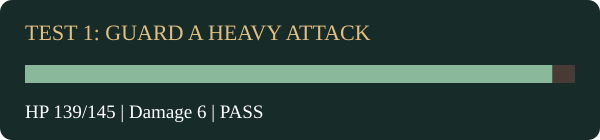

In [3]:
import copy
from IPython.display import display, HTML, SVG
p = create_player('1')
e = create_enemy(0, False)
r = combat_turn(p, e, '3', 3, random.Random(1))
assert r['received'] == 6 and p['hp'] == 139 and p['energy'] == 3
print('PASS กรณี 1: ดาเมจ', r['received'], '| HP', p['hp'], '| พลังสกิล', p['energy'])
display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="600" height="140"><rect width="600" height="140" rx="12" fill="#172b28"/><text x="25" y="40" fill="#e2bf81" font-size="22">TEST 1: GUARD A HEAVY ATTACK</text><rect x="25" y="65" width="550" height="18" fill="#483b35"/><rect x="25" y="65" width="{550*p["hp"]/p["max_hp"]}" height="18" fill="#8ab89a"/><text x="25" y="118" fill="white" font-size="19">HP {p["hp"]}/{p["max_hp"]} | Damage {r["received"]} | PASS</text></svg>'))

### กรณี 2: ใช้สกิลเมื่อพลังไม่พอ
พลังสกิลเป็น 0 คาดว่าแจ้ง ValueError และไม่เปลี่ยนสถานะของผู้เล่นหรือศัตรู

แจ้งเตือน: พลังสกิลไม่พอ ต้องมีอย่างน้อย 2
PASS กรณี 2: ไม่เสีย HP / พลังสกิล / เทิร์น


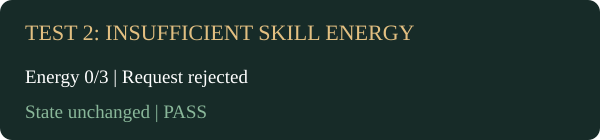

In [4]:
p = create_player('1')
e = create_enemy(0, False)
p['energy'] = 0
before = copy.deepcopy((p, e))
try:
    combat_turn(p, e, '2', 1, random.Random(1))
except ValueError as error:
    print('แจ้งเตือน:', error)
else:
    raise AssertionError('คำสั่งที่ใช้ไม่ได้ต้องถูกปฏิเสธ')
assert (p, e) == before
print('PASS กรณี 2: ไม่เสีย HP / พลังสกิล / เทิร์น')
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="600" height="140"><rect width="600" height="140" rx="12" fill="#172b28"/><text x="25" y="40" fill="#e2bf81" font-size="22">TEST 2: INSUFFICIENT SKILL ENERGY</text><text x="25" y="83" fill="white" font-size="19">Energy 0/3 | Request rejected</text><text x="25" y="118" fill="#8ab89a" font-size="19">State unchanged | PASS</text></svg>'))

### ทดสอบครบเกม 3 อาชีพ และตรวจเงื่อนไขสำคัญ
ใช้ seed คงที่เพื่อทดสอบซ้ำได้ ไม่ได้อ้างว่าทุกกลยุทธ์จะชนะ

In [5]:
completed = 0
for job in ('1', '2', '3'):
    for seed in range(10):
        demo = Game(job, seed)
        steps = 0
        while demo.mode not in ('victory', 'defeat'):
            p = demo.player
            if demo.mode == 'route':
                action = 'safe'
            elif demo.mode == 'camp':
                if p['gold'] >= 35 + p['upgrades'] * 15:
                    action = 'upgrade'
                elif p['gold'] >= 20 and p['potions'] < 3:
                    action = 'buy'
                else:
                    action = 'continue'
            else:
                action = ('guard' if demo.turn % 3 == 0 else
                          'potion' if p['hp'] <= p['max_hp'] * .5 and p['potions'] else
                          'skill' if p['energy'] >= 2 else 'attack')
            demo.command(action)
            steps += 1
            assert steps < 250
            assert 0 <= p['hp'] <= p['max_hp'] and 0 <= p['energy'] <= 3
        assert demo.mode == 'victory' and demo.player['wins'] == 9
        completed += 1
print(f'PASS: จำลองครบ {completed} เกม / ชนะครบ 9 ตัว / สถานะอยู่ในช่วงที่กำหนด')

PASS: จำลองครบ 30 เกม / ชนะครบ 9 ตัว / สถานะอยู่ในช่วงที่กำหนด


## 6. ภาพและหน้าจอใน Notebook
ภาพฝังเป็น Base64 จึงไม่ต้องมีโฟลเดอร์ assets แยก ใช้ `ipywidgets.Button` ส่งคำสั่งกลับเข้าฟังก์ชัน Python และ `HTML` แสดงภาพ/แอนิเมชัน ไม่ใช้ JavaScript คำนวณกติกา

หน้าจอตอบสนองต่อการคลิกเมื่อมี Jupyter kernel ทำงาน ใน Colab อาจต้องอนุญาต widget manager ตามข้อความของ Colab

In [6]:
ASSETS = {'enemy2': 'iVBORw0KGgoAAAANSUhEUgAAASAAAAEgCAYAAAAUg66AAAAEwklEQVR4nO3dMW7cVhhGUSnwupJSlUuvQuvRKlKqchlvzC6MIAQUSQSHw0u+d07lzgN7dPF/4Iz98AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAADwucf6BQD/+f789ee/v356eR3+5/OP+gUA8xIgIPOlfgEwu+Xsmo0LCMgIEJARICAjQEBGgICMp2Cx2T54xm8zP/lacgEBGQECMiZYwPk9J3/vb7mAgIwAARkT7CDOb3jLBQRkBAjI+ODbHd0yu3wocQzeAx9zAQEZAQIynoLtzNMuvAfWcwEBGQECMibYDpzcsI0LCMgIEJAxwTYyu1jyftjGBQRkBAjIDP9dkz1VZ/YM3wm6onu/H2b4e3cBARkBAjKegn3C0w2WvB/25QICMgIEZEyw/+HMhmO4gICMAAGZ4T/otNaZZ9cMH0g7szO8N0Z9D7iAgIwAAZmpn4Kd4bTmnLw3juECAjICBGSmm2BXPK2Xr3nUpyHMyQUEZAQIyEw3weA9V5znV+cCAjICBGRMMKZmdrVcQEBGgICMAAEZAQIyAgRkPAW7GN8Lu50nX+fhAgIyAgRkTDDuwsxhDRcQkBEgIGOCXZiZw9W5gICMAAEZAQIyAgRkBAjICBCQESAgI0BAZooPIvrAHpyTCwjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBmin+U/gz+fP4r+X1/vPyT/L5H8md7XS4gICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBGgICM74IdxPeG7sef7XW5gICMAAEZAQIyAgRkBAjICBCQESAgI0BA5rF+AUf4/vz1Z/0aYC9PL6/D/Ny6gICMAAEZAQIyAgRkBAjIDPvPcXjyBefnAgIyAgRkBAjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBGgICMAAEZAQIyAgRkHusXcAT/TTMjeXp5Hebn1gUEZAQIyAxzyq1ljnF1JhjADgQIyAxzym1hjnEVI82uJRcQkBEgIDPkWbeFOcbZjDq7llxAQEaAgMzwJ94W5hiVGWbXkgsIyAgQkJnq3NvCHOPeZptdSy4gICNAQGba028Lc4xbzDy13uMCAjICBGSchBuZY6xhdn3MBQRkBAjIOA93YI6xZHat5wICMgIEZJyKOzPH5mR2beMCAjICBGScjXdkjo3N7LqdCwjICBCQcUIexBwbg9m1LxcQkBEgIOOcvIZv9QuYxN/1C5iNCwjICBCQMcG2M4u4hbn34AICQgIEZGacYKYTI7n0lHMBARkBAjKjTTDzCt467UxzAQEZAQIyI0wwswvWO9UccwEBGQECMledYGYX3C6fYy4gICNAQOaqE2zJHIP18tm15AICMgIEZEaYYEvmGLx1qtm15AICMgIEZEabYGuYaYzktPNqDRcQkBEgIDPjBNuLKcctLj2d9uICAjICBGRMsGsw945hFh3MBQRkBAgAAAAAAAAAAAAAAAAAgHf9Al8Nqv3+l7LcAAAAAElFTkSuQmCC', 'bg2': 'iVBORw0KGgoAAAANSUhEUgAAA8AAAAHgCAIAAADlh5PTAAARq0lEQVR4nO3dPW4d1xkGYFIQgiBxkTRJYRhwISECvIEg0BYCV6q1iXSqtRDVqryLLIGpAxdJ4xR2EBiCkILONcMhr+47c2bO3/NUhGyRo5k5c1+c75uP1y+fP7sCAAAu86T2AQAAQE8EaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQOBp7QMAACby7u2rst/w9Zv3Zb8hfJIdaAAACAjQAAAQuH75/FntYwAARlC8PaMUbR6UZQcaAAACAjQAAAS0cAAAazTbsHEJTR1sYQcaAAACAjQAAAS0cAAAn9Z1w8YlNHVwOTvQAAAQEKABACCghQMAuG/4ho1LaOrgMXagAQAgIEADAEBACwcA8BOdGw/Sy8E9dqABACAgQAMAQEALBwDMTufGhfRycMsONAAABARoAAAIaOEAgEnp3FhNL8fk7EADAEBAgAYAgIAWDgCYi86NgvRyzMkONAAABARoAAAIaOEAgCno3NiVXo6p2IEGAICAAA0AAAEtHAAwMp0bB9PLMQM70AAAEBCgAQAgoIUDAAakc6M6vRwDswMNAAABARoAAAICNAAABARoAAAICNAAABAwhQMAxmH4RoOM4xiPHWgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIApHADQPcM3umAcxzDsQAMAQECABgCAgAANAAABARoAAAICNAAABEzhAIBeGb7RKeM4emcHGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACFy/fP6s9jEADfnji9/dfvHXm3/WPRLgMe/evqp9CJTx+s372ofAGnagAQAgIEADAEBAgAYAgIAADQAAAQEaAAACT2sfANCE0/CN5Z8YxwEAd9mBBgCAgAANAAABARoAAAICNAAABARoAAAImMIBU1sO3zjz/xjHAQBXdqABACAiQAMAQECABgCAgAANAAABARoAAAI7TuHw5j4065LhG2f+lkUNwMzsQAMAQECABgCAgAANAAABARoAAAICNAAABMpP4Vi+3e/NfWjEuuEbZ76PRQ3AhOxAAwBAQIAGAIDAjr9IBQDYw+s372+/ePf2Vd0jYZ3TFaRTdqABACAgQAMAQKBYC8clb/d7cx+qKDV848x3tqgBmIcdaAAACAjQAAAQEKABACAgQAMAQECABgCAwNYpHOve7vfmPhxgv+EbZ36WRQ1Qlgdsg+xAAwBAQIAGAIBAsV+kAgAc7PWb97dfvHv7qu6RcInT9aJ3dqABACAgQAMAQGBlC0ept/u9WArFHTl848xPt6gb5OpAR5YPc0u4HXagAQAgIEADAEDAFA4A6J5xHC0zfGM8dqABACAgQAMAQCBr4djv7X4vlsJGdYdvLFnU7fAuP3Tkkoe5JVydHWgAAAgI0AAAEDCFAwDGYRxHOwzfGJgdaAAACAjQAAAQuKiF48i3+71YCpHWhm8sWdS1eJcfOrLuYW4J12IHGgAAAgI0AAAETOEAgAEZx1GL4RszsAMNAAABARoAAALXL58/e+y/NfJ2vxdLYamR5bmORb2rjfeGqzMwvRy7Wte5Ufxhbgkfww40AAAEBGgAAAiYwsEaJrcDdMdcjj2YuTEnO9AAABAQoAEAIPDAFI5m3+7XLdAOLRy1NLs813H/FORdflbQy7Haxs6NAx7mlvCu7EADAEBAgAYAgIApHASWJSe9HAAtWPc0NpcjZeYGt+xAAwBAQIAGAIDAz1M4Onq7X7dALWduEhdlVx0tz3XcP6t5l59bpRrq9HI8qFTnRpWHuSW8BzvQAAAQEKABACBgCgefdknJyTgOgOMVH45kLsddZm7wGDvQAAAQEKABACBw/Zc//6n2MaynW+AY0VvDLkpBww/fWHL/XMi7/Nw6cjjS8E0d+zVsNPIwt4QLsgMNAAABARoAAAKmcPCodSUn4zgA9lZlONKyw6Hrpg4TNtjCDjQAAAQEaAAACPQ9heNEt8AeNr417KKs1sj72nW5fx7UyL3h6lTX7HCkZps6qjRsNLJglyzh7exAAwBAQIAGAICAKRzcV6rkZBwHQFntD0e6pFOieJuHeRoczw40AAAEBGgAAAgMMoXjRLfAdsXfGnZRLtTs+9p1uX+uGr43XJ2DGY7UhWYX7JJbYjU70AAAEBCgAQAgYAoHP9mv5GQcB8AWhiNBa+xAAwBAQIAGAIDAaC0c6lN0p6P3tauYeVG3f2/MfHXgnvYX7JIlvJodaAAACAjQAAAQGK2Fg9SRJSelIoDLGY4EzbIDDQAAAQEaAAACw7ZwqE/RuB7f165rnkXd470xz9WBe3pcsEuWcMoONAAABARoAAAIDNvCwXl1S05KRQCPMRwJ2mcHGgAAAgI0AAAExm/hUJ+iKWO8r13XqIt6jHtj1KsD94yxYJeqLOE/fPGb2y/+9vd/HfZD1zmdHzvQAAAQEKABACAwfgsHd7VWclLtBbhlOBKzOXVuLP+k/V4OO9AAABAQoAEAIDBRC4f6FBW11jwzhjEW9aj3xhhXB+4ZdcEu1V3CrfVyLK+7HWgAAAgI0AAAEJiohWNm7Zec2q/2biwnNfvvunmy5iHw4uOH4kcCc2rt+dz+05jeLYdv9MgONAAABARoAAAIzNjCoT7F5boe807LWivc78cjlwHMs2CXZh7Hcea624EGAICAAA0AAIEZWzjm0WPJqaNqr14OYLX2n88dPY3pwsbhG6195tqBBgCAgAANAACBqVs41Kd4TFRpaq2uRMvaL9zvxyOX7sy8YJcaWcIHfOZect3tQAMAQECABgCAwNQtHKMao+TUSKkIoKAen8+exmyxcfjGJd+5Sv+kHWgAAAgI0AAAENDCcXWlPsX/DDbmnXb0WLjfj0cujbNgz2ttCZf68I2uux1oAAAICNAAABB4Wmr7/ebJmm6QFx8/3PuT/d7WXBqszj5qyam1UtEl9HIAd43xfO7xaUwtR8a5KuxAAwBAQIAGAIBAK1M4ht/qp2WjjnmnujEK9/vREkBTLNhUa0t43WfuuutuBxoAAAICNAAABCq3cNTt3BijvD5Pyal4qejI22+Mmw2IjPp8bq1wTzsa6cg94DPXDjQAAAQEaAAACLQyhaMu5XUO42abwaiF+/1oCaAiC3a70zn87ocf6x7JPWc+czdedzvQAAAQEKABACCgheP/dFRen7nktLHaO887wkAV8zyf9d7Qi+KfuXagAQAgIEADAEBAC8fDlNeB1DyF+/1oCeAwFuwefvvrX9x+0do4jpNS190ONAAABARoAAAIaOH4hNZ6OZSc7oqqvY0M31hq7R4D1pn5+dxj703dOU5nHvg3T9ZksxcfP6w/mrWa/WA9gB1oAAAICNAAABDQwgGt0MvRqZkL9/vpsSUALtf1A7/Hzo3TeJBS7EADAEBAgAYAgMD1y+fPinyjdS+Nfv35Z0V++pGqVFvUiC+0rPb2WGk6OeBm6+h1765VuQ+/+fb7FX9rjIt7ZH3c8/lBg/XeHLCET/dq+4/lHj9YtXAAAEBNAjQAAARM4YgdWRnssUrSiDFOXdevacPxlgvfImKLIz9KTj/rZlXz1QF6/GAt3rlxYgcaAAACAjQAAAS0cKx3QGVwv9LDqE6vw3/3w491j6QsZehO9VjxHFXxRWT4xnl+FQ5jswMNAAABARoAAAJaOAooXhlU9uUxejlgKXpmWkR8kk/hu3o8Gwd0wNqBBgCAgAANAAABLRwllaoMGr6x3ekcDjaOo0cTVsx7rHj2aON5XndnGr6RMo6jU10/x4p/9C+fEnagAQAgIEADAEBAC0dDui6XcLD2+yKW93P7x7zRGEu4/ctU/Dy3/0/mGGMsYfawfErYgQYAgIAADQAAAS0cu1hXEDR8Yw/Dj+Norfp8SQ20tWPmQRNepjP/ZMM3tmt2HIfOjbucjfNO58cONAAABARoAAAIbG3hOG1l33z7/dZjGdElNdDT/9Nsj8E3qy7u159/tuWHXlI1Vmm6q8eCe4/HvDT8fdjIZTryPDfyTwaaZQcaAAACAjQAAARM4TjIsiA4fNl3ozMlVKfuvCrV540XZfnXlc4b1OOttZHhG3toZBzHYB8lG5fnYGfjAHagAQAgIEADAEBgZQuHrf7VnLqU1+FXO+DU7Xc/t3/dZ17L7V+dUs4MR6r7b795subje+NwpOImbAo6wDzLsy470AAAEBCgAQAgYAoH3Ri+7raf4hW9mX+lhfvwrv2uTvvnubU7s2tOZi3tL7Rm2YEGAICAAA0AAIGshcNWP1CLIu8MevyUcWcWNHNTUHHuzF3ZgQYAgIAADQAAgYtaOCYsfMCQxqjo+eULDdp4UcY4vWOsr0aUOplj3FobLU+m07KdHWgAAAgI0AAAEPCLVGBGp/rdzbffVz2QTQ6omCt0prQxXB0ySqLrlRtxRxXkgVaQHWgAAAgI0AAAEDjXwmGrH+jC8mGl2lvdJZX34T9ljJIoKDqZzhh7swMNAAABARoAAAKmcAAD8ns92uGXOFwZJVHUmZM54a1FLXagAQAgIEADAEDggRYOFRBgGErn7fDhcmWURFFWNxXZgQYAgIAADQAAAVM4gCn4vR40xSiJgpwxjmcHGgAAAgI0AAAEfm7hUAEBZuD3etAUoySgR3agAQAgIEADAEDAFA5gUjo3aIobEjpiBxoAAAICNAAABJ6qGQEAwOXsQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABK6/+uLLIt/oH7/65Yq/9ft//6fIT2dXLu7AXNyBubgDc3EH5uJ2wQ40AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAAC11998WXtYwAAgG7YgQYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQOC/mrTdBDiwJvYAAAAASUVORK5CYII=', 'bg1': 'iVBORw0KGgoAAAANSUhEUgAAA8AAAAHgCAIAAADlh5PTAAARwUlEQVR4nO3dvY5d5RUG4DORnYImAUUgUUUOMRW34JtBoqNKkVxCUqSiQ+LCUIiU2opM0rgITYpBx8Z7Znu/+3x7f3/PU43A4znef+fVWmvWuXv+7MUFAADY5le1XwAAAPREgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAASe1H4BAMBEvv3mu7J/4Vdff1n2L4T3UoEGAICAAA0AAIG7589e1H4NAMAIio9nlGLMg7JUoAEAICBAAwBAwAgHALBHswMbWxjq4BYq0AAAEBCgAQAgYIQDAHi/rgc2tjDUwXYq0AAAEBCgAQAgYIQDAHjX8AMbWxjq4DEq0AAAEBCgAQAgYIQDAPiZyY0HmeXgHSrQAAAQEKABACBghAMAZmdyYyOzHNxTgQYAgIAADQAAASMcADApkxu7meWYnAo0AAAEBGgAAAgY4QCAuZjcKMgsx5xUoAEAICBAAwBAwAgHAEzB5MahzHJMRQUaAAACAjQAAASMcADAyExunMwsxwxUoAEAICBAAwBAwAgHAAzI5EZ1ZjkGpgINAAABARoAAAICNAAABARoAAAICNAAABCwhQMAxmH5RoOs4xiPCjQAAAQEaAAACAjQAAAQEKABACAgQAMAQMAWDgDonuUbXbCOYxgq0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAVs4AKBXlm90yjqO3qlAAwBAQIAGAIDAk9ovAACAR/3h93+8/+Kf//pH3VfClQo0AAAEBGgAAAgY4QCA7v3t73+9/+LPf/pL3VcCM1CBBgCAgAANAAABIxwAAM25Lt9Y/hfrOKpTgQYAgIAADQAAgbvnz17Ufg0AQODbb767/+K6fGPJOo4ufPX1l4/9r+UIx5URjupUoAEAICBAAwBAwBYOAIBWrExuLP+MWY5aVKABACAgQAMAQMAIBwB0ZmX5xvLPWMcBxalAAwBAQIAGAICAEQ4AgMq2LN9Y+S7rOE6mAg0AAAEBGgAAAkY4AKAP+7r81nFAcSrQAAAQEKABACBghAMAoI59Yzkrf491HOdQgQYAgIAADQAAASMcANC0Ul1+6zigFBVoAAAICNAAABAwwgEAcKrrOE1x1nGcQwUaAAACAjQAAASMcADMQm+3L6WWbyxZxwE3UoEGAICAAA0AAAEjHAAAZzhu+caSka1DqUADAEBAgAYAgIARDoDBLZc56O227LjlG0vWccA+KtAAABAQoAEAIGCEAwDgQGcu31gysnUEFWgAAAgI0AAAEDDCATCmLcsc9HbbcebyjSXrOCCiAg0AAAEBGgAAAkY4AADKq7t8Y8nIVkEq0AAAEBCgAQAgYIQDYCj7ljno7dZSd/nGknUcsIUKNAAABARoAAAIGOEAACimteUbS0a2bqcCDQAAAQEaAAACRjgARlBqmYPe7jlaW76xZB0HrFCBBgCAgAANAAABIxwAALdqf/nGkpGt3VSgAQAgIEADAEDACAdAx45b5qC3e4T2l28sWccBSyrQAAAQEKABACBghAP4BY17gO16XL6x5MmfUoEGAICAAA0AAAEjHAD9OXOZg97u7XpcvrFkHQdcqUADAEBAgAYAgIARDuByeajFrHEP8Jgxlm8sefJvpAINAAABARoAAAJGONhDiweqqLvMwY2fGmP5xpJ1HKACDQAAAQEaAAACRjhgaltazBr3APdGXb6x5Mm/TgUaAAACAjQAAATunj97Ufs10I2Vdr8WT6eiLQHOci3NLnNwSTyo2fN1nOHXcXz19Zf3X0x4ct3mD1KBBgCAgAANAAABWzhgRvu6kH4pG5jKzJMbV578D1KBBgCAgAANAAABWzh4P4saxnNjO9JZPkdHXWOXxKWr83WcrtdxXAc2lpzci9v8l1SgAQAgIEADAEDAFg6YSKkupF/KBnq3MrBxZXLjbZ78b1OBBgCAgAANAAABWzh4lEUN4ynejnSWj9B113jCS6Lr83Wc1tZxbBnYWHJyHzThbb6kAg0AAAEBGgAAArZwwPiO60L6pWzgQSsjE99+891pP2sfkxvrPPkvKtAAABARoAEAIGALB++yqGE8J7QjneXbDdY1Hv6SGOx8HafHK8HJ3ajHk1uKCjQAAAQEaAAACNjCAcM6swvpl7KB3pncSM385FeBBgCAgAANAAABIxz8zGdtQBWjdo1HvfFHPV/HGfVKYHIq0AAAEBCgAQAgYIQDRlO3xaxdC/TFWM7tJnzyq0ADAEBAgAYAgIARjtn5rA2oYp6u8Rg3/jzn6zhjXAlwTwUaAAACAjQAAASMcMAgWmsxa9cCLWvtmTmGeZ78KtAAABAQoAEAIHD3/NmL2q+BChppXQ3f4jlTI+d0yVl+W7On6UwdXRLO16E6uhLO9Orpyx3f9dFPHxd/JaxQgQYAgIAADQAAAVs4oG/tt5jn+aVsxtPsRavLD3WpQAMAQECABgCAgBGOubTW7tfcZxKt3Xp1ufGB3qlAAwBAQIAGAICAEY4pfPSbD2u/BArrcSRA4x6AMahAAwBAQIAGAICAEY4pfPjh72q/hPfQ3GdIPU7anMmND3RKBRoAAAICNAAABIxwjMzyjfGMMRKgcQ9A11SgAQAgIEADAECgyxGO62TCq//+WPeVNK795RtLmvsMYIxJmzO58YG+qEADAEBAgAYAgEBPIxzLnRJmOR5k+cZ4Rh0J0LgHoEcq0AAAEBCgAQAg0NMIxwqzHG/rcfnGkuY+3Rl10uZMbnygCyrQAAAQEKABACBw4AhHqU5ctFNi5lkOyzfGM89IgMY9AB1RgQYAgIAADQAAgUG2cCzNM8tx/ZeOsXxjSXOfxs0zaXMmNz7QMhVoAAAICNAAABAoP8Kx7Gbu68TZKcG0Zh4J6LFx3+xLffX05Y7v+uinj4u/EoAVPY7dqkADAEBAgAYAgEBzWziKT2702BfYYvjlG0s9NvfZbdQ7F4B7y8jX0ZNfBRoAAAICNAAABIqNcGzZG1C3Bd9RX4A5zbx8Y2k5m+TOBZhE+5lNBRoAAAICNAAABFrZwnHmx6a03xdYMeHyjaUqs0BdXzZjcAoABhBFvmaf/CrQAAAQEKABACBw6wjHvr0BjXwiRrN9Adpxwpp3yzfWXaeVfvzx3/dfuHMBunPjsG5rT34VaAAACAjQAAAQqLyF48zlGyta6wssWb7xIB/NMzmnAGA2jTz5VaABACAgQAMAQGDnCEepvQHL36+vq5G+ANWdsObd8o3UyuPCnQvQpuOGdes++VWgAQAgIEADAECg8haOZjXSEbZ8Y6NS6zgGW/MOAFWcuWatypuvCjQAAAQEaAAACGQjHMftDWhtHcdVlb5AI58vw24rl43lG7ezjgOApTPfAlSgAQAgIEADAEDAFo6tqrSGLd9I7VvHMeqa95k58gDna2QG9YS3ABVoAAAICNAAABDYNMJx5t6AZtdxnKCRxsc8zjzglm8cYcvjwiwHwLSOewtQgQYAgIAADQAAAVs4Yid0hC3fuN2+dRzHWc4YNDJR8Orpyx3f9dkHnxd/JUczywEcauaHTPszqMXPjgo0AAAEBGgAAAisjXDU3RvQ/jqOUu2A9hsfg2nkgM/c7KvLkQcKWr6nzPOQaeT9NFLq7KhAAwBAQIAGAICALRwFlGoHWL5xhOsk0vCzQKQceWC3LdMLHjItu/HsqEADAEBAgAYAgMADIxx1l28stb+O4ypqByy7P83+A394/f2O7yr1WRulOl/t/7Lwmc2+Nz/r9Z4PUhmMNitwqOUbUNdPm/bfTyP73gJUoAEAICBAAwBAwBaOQ6y0AwZrfJzgxvZ6jwfcREEtjvwwnEoOUuo9pcdLtMf300h0UlSgAQAgIEADAEDgzQhHa8s3ljpax3HVY4+mWTcuOelR8etnjMMCj1le4R7CFHHcw9Ml2ikVaAAACAjQAAAQsIXjJFrnBU3Y8JpwFUldE15jXdtyhQ/2SRbHcfG/7cyHZ7OfbzXhO8jKXXAdeFaBBgCAgAANAACBJ+0v31jqcR0HR1g2WYbvNOmunqzuAXe61914vzu8b7PAhHcM/366xcpdoAINAAABARoAAAK2cDCCCTtNW7qrEx6W45zZztZMP9nMh9cCkwd5ePKO5cCzCjQAAAQEaAAACPQ9wmEdB8zcfa7iuAOumb7Rce31ee4mC0weZHLj4iBspgINAAABARoAAAJ9j3AAV/puJyvVxdZM3+jMK3zUUZnix3CMy8/D8+IgPOI6KrykAg0AAAEBGgAAAoOMcFjHAdSyr4utmb5RI53lUQ9vKT0OvTRyadEpFWgAAAgI0AAAEBhkhAOgui1d/hO6xm9exuuXR/+s4zTbXjfLsZEDdbJGZsnGsLJ840oFGgAAAgI0AAAERhvhsI4DoF8dNZSNKGzU2oHq6Brbp7UDPioVaAAACAjQAAAQGG2EA6C6ZQt1+K7xjbo+Pj1+hkgVdQ9U19fYPiuzHBMejS22LN+4UoEGAICAAA0AAIFhRzis4wCq0yedkzUIG51woNyDFwfhGCrQAAAQEKABACAw7AgHAI0bvrNslmOj4gdq+EuLgqLlG1cq0AAAEBCgAQAgMP4Ih3UcANud8GkXE7bXfdjKRg4UvVCBBgCAgAANAACB8Uc4ALhFqQ0JE05urNh3VN981+uX5V9Tk6ID5Rpju33LN65UoAEAICBAAwBAYKIRDus4AG5x49QBD9pyVB3Dy+qBcnw4nwo0AAAEBGgAAAhMNMIBQBFbPu1CVz1VatvJ8Fxa3OLG5RtXKtAAABAQoAEAIDDjCId1HABlGT8oyIgCtE8FGgAAAgI0AAAEZhzhAOAgxg+ABpVavnGlAg0AAAEBGgAAAlOPcFjHAQBASgUaAAACAjQAAASmHuEAAGBUxZdvXKlAAwBAQIAGAICAEY7LxToOAAA2U4EGAICAAA0AAIEnpYYWfnj9/Y7v+uyDz4v8dAAAuBy5fONKBRoAAAICNAAABGzhAABgHCcsVVOBBgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgMDdp598UeQv+t9vf9rxXb/+z9MiP51DObkDc3IH5uQOzMkdmJPbBRVoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAE7j795IvarwEAALqhAg0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgMD/AUcU2P20d+MiAAAAAElFTkSuQmCC', 'enemy1': 'iVBORw0KGgoAAAANSUhEUgAAASAAAAEgCAYAAAAUg66AAAAExUlEQVR4nO3dMW4UWRhGUXvEQmZRnmRWQWqJ0BIpqyDBi5qdQIBGU5LHUKqurlv13jkRGS1oX/2fqhseHgAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAB+77F+AcB/Pn96/f7vr59fnob/+fyjfgHAvAQIyHyoXwDMbjm7ZuMCAjICBGQECMgIEJARICDjKVhstg+e8dPMT76WXEBARoCAjAkWcH7Pyd/7Wy4gICNAQMYEO4jzG95yAQEZAQIyPvh2R7fMLh9KHIP3wK+5gICMAAEZT8F25mkX3gPruYCAjAABGRNsB05u2MYFBGQECMiYYBuZXSx5P2zjAgIyAgRkhv+uyZ6qM3uG7wRd0b3fDzP8vbuAgIwAARlPwX7D0w2WvB/25QICMgIEZEyw/+HMhmO4gICMAAGZ4T/otNaZZ9cMH0g7szO8N0Z9D7iAgIwAAZmpn4Kd4bTmnLw3juECAjICBGSmm2BXPK2Xr3nUpyHMyQUEZAQIyEw3weA9V5znV+cCAjICBGRMMKZmdrVcQEBGgICMAAEZAQIyAgRkPAW7GN8Lu50nX+fhAgIyAgRkTDDuwsxhDRcQkBEgIGOCXZiZw9W5gICMAAEZAQIyAgRkBAjICBCQESAgI0BAZooPIvrAHpyTCwjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBmin+U/gw+/v1P8vt++fpn8vseyZ/tdbmAgIwAARkBAjICBGQECMgIEJARICAjQEBGgICMAAEZAQIyvgt2EN8buh9/ttflAgIyAgRkBAjICBCQESAgI0BARoCAjAABmcf6BRzh86fX7/VrgL08vzwN83PrAgIyAgRkBAjICBCQESAgM+w/x+HJF5yfCwjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBGgICMAAEZAQIyAgRkBAjICBCQeaxfwBH8N82M5PnlaZifWxcQkBEgIDPMKbeWOcbVmWAAOxAgIDPMKbeFOcZVjDS7llxAQEaAgMyQZ90W5hhnM+rsWnIBARkBAjLDn3hbmGNUZphdSy4gICNAQGaqc28Lc4x7m212LbmAgIwAAZlpT78tzDFuMfPUeo8LCMgIEJBxEm5kjrGG2fVrLiAgI0BAxnm4A3OMJbNrPRcQkBEgIONU3Jk5NiezaxsXEJARICDjbLwjc2xsZtftXEBARoCAjBPyIObYGMyufbmAgIwAARnn5DX8Vb+ASXyrX8BsXEBARoCAjAm2nVnELcy9BxcQEBIgIDPjBDOdGMmlp5wLCMgIEJAZbYKZV/DWaWeaCwjICBCQGWGCmV2w3qnmmAsIyAgQkLnqBDO74Hb5HHMBARkBAjJXnWBL5hisl8+uJRcQkBEgIDPCBFsyx+CtU82uJRcQkBEgIDPaBFvDTGMkp51Xa7iAgIwAAZkZJ9heTDlucenptBcXEJARICBjgl2DuXcMs+hgLiAgI0AAAAAAAAAAAAAAAAAAALzrB3y1rwtlosFQAAAAAElFTkSuQmCC', 'boss2': 'iVBORw0KGgoAAAANSUhEUgAAASAAAAEgCAYAAAAUg66AAAAGS0lEQVR4nO3dPY7dZBiG4QRR0yJByR5ooSIVHWyCtCyDNmwCulShgpY9UIJEywagiIgsDh555ti+bX/XVU2k6OhoZs6j95nvx8+eAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAwH89n/7j+68++/vfr7/58Zfnt/8d4D7TnHmvfCPA2AQQkJmtYHNUM2CJJXliAgIyAgjIzNapJePTlGoGY7onK0xAQEYAAZn313ohK2hwPY+tV49lAgIyAgjIrFbBlpgb51QzaG1dteaYgICMAAIyu1awOaoZ7KOqWnNMQEBGAAGZRRXnaGObagYPO8tn1gQEZAQQkDnEKthjOXfGyI5Wr+5hAgIyAgjInLKCLWFz48PevPzyMmP81ItXry/z871S1ZpjAgIyAgjIXLaCzfH4aY5shNo1ZQICMgIIyDy6glxpRBytgl115WvOGVfERvt8mYCAjAACMsOtgk1ZEeMIrlS7HssEBGQEEJARQEBGAAEZAQRkht6IOOdKK2KjbT6cc7RNiT5Hb5mAgIwAAjKP3og4HatGGCOB5R775wsTEJARQEBm6LNgc5wRYwv+ZHHLBARkBBCQuatejDZSnqWO2Xz4sD03JfqMPMwEBGQEEJARQEBGAAEZAQRk7tqIONq5MBsUWWKEz8LUPZ8FExCQEUBAxlmwi7D5cLnp9+poNyWOxgQEZAQQkFHBnuiMK2JffPv56q/503c/r/I6R35vS4y28rUWExCQEUBARgABGQEEZAQQkFltFWy0c2FT1YqYzYf3u2dT4mi/51Nr/Z6bgICMAAIyAgjICCAgI4CAjLNgKzvjGTGWG3nlawsmICAjgIDMJhXBmHprrTpm8+E+ppsS/T7fshEROD0BBGQ2WQUb+VwYXNUWq7omICAjgICMjYg7sUHxXPzpYB8mICAjgICMCnYCNh/u75MPP3j39W9//hW+k2szAQEZAQRkVLCAFTF4ywQEZAQQkNm8gjkXBue19Z8ITEBARgABGatgMStijMwEBGQEEJBRwQ5EHWM0JiAgI4CAjAACMgIIyAggIJOttDgXttz0dj72N9qNiHuuwJqAgIwAAjICCMgIICAjgICMAAIyAgjICCAgI4CAjAACMgIIyBzi1j3nwh7mLFhrhLNg1Q2cJiAgI4CAjAACMgIIyAggIOO5YAe19crXR59+vOnr7+mPX3/f9PWnP4sRVsT2ZAICMgIIyAggICOAgIwAAjKHWAWbnkNxLgz2UZ3/mjIBARkBBGQEEJARQEBGAAEZAQRkBBCQEUBAJt+I9JCRNyVucR3Hla7gmLP11Rxnv47jCJsPp0xAQEYAAZlDnAWbMzcujlzNYImjVa05JiAgI4CAzKEr2BzXd8Cts9SuKRMQkBFAQOaUFWzKShmjOWPVmmMCAjICCMicvoLNsVLGlVypdk2ZgICMAAIyl61gU+oYZ3TV2jVlAgIyAgjIDFHBpmxc5GhGqFpzTEBARgABmeEq2BwrZexp5No1ZQICMgIIyKhg/0MdYwtq1y0TEJARQEDGSPhEW1eztR7NPMLjmOds8ZjmJY9mVrWWMwEBGQEEZKyCPZGVMqbUrqcxAQEZAQRkVLAVuOJjHKrWukxAQEYAARkVbENWyuBhJiAgI4CAjAq2E3UMbpmAgIwAAjIqWMDGRXjLBARkBBCQUcEOZK1bENnOm5dfvqvJL169di7sTiYgICOAgIwAAjICCMgIICAjgICMAAIyAgjI2Ih4QSM/jnlq+n3Y4jHN3M8EBGQEEJARQEBGAAEZAQRkBBCQEUBARgABGQEEZAQQkBFAQEYAARkBBGQEEJBxHccFuXqCszABARkBBGQEEJARQEBGAAEZAQRkBBCQEUBA5nn9Bljk6/oNDOKH+g2MxgQEZAQQkFHBnk4t4h7q3jMTEBASQEBmxAqmOnElp65yJiAgI4CAzNUqmHoFtw5b00xAQEYAAZkrVDC1C5Y7VB0zAQEZAQRkzlrB1C64X17HTEBARgABmbNWsCl1DJbLa9eUCQjICCAgc4UKNqWOwa1D1a4pExCQEUBA5moVbAk1jSs5bL1awgQEZAQQkBmxgq1FleMep65OazEBARkBBGRUsHNQ9/ahFu3MBARkBBAAAAAAAAAAAAAAAAAAALP+AQvlbeuTathvAAAAAElFTkSuQmCC', 'boss0': 'iVBORw0KGgoAAAANSUhEUgAAASAAAAEgCAYAAAAUg66AAAAGAElEQVR4nO3dMW4bVwBFUTtwn21lAwlUpxagtQhQnVpINpBtZQVKkQQYUBZDcTi88/+cU7kx8ccYP7zHkcgvXwAAAAAAAAAAAAAAAADYu6/1AdZ6eH582/L1X59ehv83YhxHu59/qA8AHJcAAjICCMgIICAjgICMAAIyAgjICCAgI4CAjAACMgIIyAggICOAgIwAAjICCMgIICAjgICMAAIyAgjICCAgI4CAjAACMgIIyAggICOAgIwAAjICCMgIICAjgICMAAIyAgjICCAgI4CAjAACMgIIyAggICOAgIwAAjICCMgIICAjgICMAAIyAgjICCAg860+wN49PD++/ffn16eXr+VZYDYaEJARQEDGBPsEc4wtLO+ro9GAgIwAAjLTzoh71lpzjM/a4v4c8T7UgICMAAIyw1W2c6qnCSNWX+7P2wLvaUBARgABmSFq2jXMMfZgDz9kuOd7UgMCMgIIyOy2mt2SOcY9mV2X04CAjAACMkPUtFsyx9iC2XUdDQjICCAgM1xluyVzjDXMrvU0ICAjgIDM0PVtLRWaz3LP3JYGBGQEEJCZpsqtpVrzEffGdjQgICOAgMyUtW4tlRv3wH1oQEBGAAGZ6SveWnuo4hzHEWbXkgYEZAQQkDlU3VvLHGMLR5tdSxoQkBFAQOaw1W8tc4w1jjy7ljQgICOAgIwaeAPmGJcwu97TgICMAAIyKuGNmWMsmV3naUBARgABmW/1AWA2ZtflNCAgI4CAjKq4IU/EjsPsuo4GBGQEEJBRG+/EHJuP2bWeBgRkBBCQEUBARgABGQEEZAQQkBFAQEYAARkBBGQEEJARQEBGAAEZAQRkBBCQEUBARgABGQEEZHwv2MB+++nHTV//1z//2vT1l2a6Fi6nAQEZAQRkBBCQEUBARgABGQEEZAQQkBFAQEYAARkBBGQEEJARQEBGAAEZAQRkfBzHwGb6iImZroXLaUBARgABGQEEZAQQkBFAQEYAARkBBGQEEJARQEBGAAEZAQRkBBCQEUBARgABGQEEZAQQkBFAQEYAARkBBGQEEJARQEBGAAEZAQRkBBCQEUBARgABGV/NvKGH58e3+gywZxoQkBFAQOZrfYDZmF3H9Pr04v/SFTQgICOAgIzaeANmF0vm2OU0ICAjgICMqngls4tLmGPnaUBARgABGfXwE8wu1jDH3tOAgIwAAjIq4f8wu9iCOfYPDQjICCAgowZ+h9nFPR15jmlAQEYAAZnDVr9TZhd7cLQ5pgEBGQEEZA5V906ZXezZEeaYBgRkBBCQmb7inTK7GNGsc0wDAjICCMhMWetOmV3MZKY5pgEBGQEEZKapcqfMLo5g9DmmAQEZAQRkhq5vp8wujmzEOaYBARkBBGSGq2ynzC54b5Q5pgEBGQEEZIaoaafMLrjcnueYBgRkBBCQ2W01OzXi7FpW3xHPz3z2Nsc0ICAjgIDMrurYqRFny0cVd8Rr4bzRJ/Ye5pgGBGQEEJDJK9ipWavsiNfFeTPN7WqOaUBARgABmV1MsCNU1hGvkfNmnd73nGMaEJARQEAmm2BHq6YjXi/nHWGGbz3HNCAgI4CAzF0n2JEr6IjXznlHm+RbzDENCMgIICDjKdh3bFE193y9XOfI8/xW164BARkBBGT8Lti/tv6Bqz1cI7d1tKnuKRgwFQEEZHYxwZbuWUHv+bEDe67WXOcIs93vggHTEkBAZncTbGmLCrqH70K6ws/1AQ7ij/oAH5n1rQkNCMgIICAzzBxZU0E3qpRmEWtcPfdmemtCAwIyAgjIDDPBli6poGcqpenENB6eH3+/9u/u4YmwBgRkBBCQySvYWss59vr08kt5FihdMsf2MLuWNCAgI4CAzK7q2JU81YITyzl28tbErn7fTQMCMgIIyIw6wcwuWC+fYxoQkBFAQGbUCbZkjsHl8tm1pAEBGQEEZGaYYEvmGLy3q9m1pAEBGQEEZGabYJcw05jJbufVJTQgICOAgMwRJ9itmHKsMfR0uhUNCMgIICBjgo3B3LsPs+jONCAgI4AAAAAAAAAAAAAAAAAAAPjQ37kcU2M4MOEqAAAAAElFTkSuQmCC', 'hero3': 'iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAAEhUlEQVR4nO3dv4odZRjA4VUEL0KwC1baeQdaBFslN2GXC1j2AtJ5DUJwW0mhYq/dppJ0C2ntt9LWM8IZPs6ZP+f8nqcLJGGSbH6837szc25uAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAoOODrS+g5vb1q3+2voZLdvfipa/ZM/pw6wsAtiMAECYAECYAECYAECYAECYAECYAECYAECYAECYAEPbR1hfAmN9/+2PrS+CKmAAgTAAgTAAgTAAgTAAgTAAgTAAgzH0AcMS7N7dD73B89vzuot5ZaAKAMAGAMAGAMDsAOOLjTz4/+PHT+7dHf/7czmBvOwITAIQJAIQJAITt6jzCzc1fv/yQ/uzAz77+fldfk48P9wf/HnM7gFFb7wRMABAmABAmABDmPgAYMD2zjz4rMDX99WvvBEwAECYAECYAEGYHACeYO7OfuiNYmgkAwgQAwgQAwuwAYEGj9w2sfV+ACQDCBADCBADC7ABgx5beCZgAIEwAIEwAIMwOAFZ07vcJnMoEAGECAGECAGECAGECAGECAGECAGHuA4ANbf2+ABMAhAkAhAkAhNkBrOz29atdvyd+a3N/P3cvXq762XnXzgQAYQIAYQIAYXYAO/Pj309bXwIhJgAIEwAIEwAIEwAIEwAIEwAIEwAIc1/1wtz7v6ylnw14fLg/+Pf79ItvV/0/M/q5AaPvBzABQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJgAQJjPBTgzz/+va/r37bMDx5gAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIMw7AU/kHYD74h2BY0wAECYAECYAEGYHADvy7s3t0E7p2fO7k3YcJgAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAI8yzAIM//XxbvBzjOBABhAgBhAgBhdgCwobWf/58yAUCYAECYAECYAECYAECYAECYAECY+wBgRaPf91+aCQDCBADCBADC7ABmeP7/ulza+wHOfe//lAkAwgQAwgQAwuwAYEFbP+8/xwQAYQIAYQIAYXYAcIK93ds/ygQAYQIAYQIAYbu+D7roy6++WfVM+eevP5/0NXBp1zvq8eH+4M/39P7tWX//tb/vP2UCgDABgDABgDD3AcCKtj7zT5kAIEwAIEwAIMwOAI4Y/b7/3s74c0wAECYAECYAEGYHAEdc2pl+lAkAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwrwTkO+2vgC2YwKAMAGAMAGAsKt+5/lKnKEvy09bX8CemAAgTAAgTAAgzA5gnjN+S2pHYAKAMAGAMAGAMDuA/3Pm57+ueidgAoAwAYAwAYAwO4B5dgItV33mnzIBQJgAQJgAQJgdwOnsCC5L6ow/xwQAYQIAYQIAYXYA+2OncMiZfUEmAAgTAAgTAAAAAAC4cv8C4l+gDIxJnS4AAAAASUVORK5CYII=', 'hero2': 'iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAAE2ElEQVR4nO3doY4eVRiA4S0h4QrAEwRXwF4BiAZNUARXha6oQFZgQdWRSoIkCDDY7RUgCJcCdpkmnPyZ/585M+/zuAqS6QJvvu9k5uyTO3jk1cuHfx7/+dmL+yd7PQu3987eDwDsRwAgTAAgzH4Xt9z5R5wJnIsJAMIEAMIEAMLsczGX7vwjzgSOzQQAYQIAYQIAYfa3k7v2zj/iTOBYTAAQJgAQJgAQZl87ma13/hFnAnMzAUCYAECYAECY/ezgZtv5R5wJzMUEAGECAGECAGH2sYM52s4/4kxgXyYACBMACBMACLN/TeZsO/6lnAlsywQAYQIAYQIAYfatndV3/pFbnwn8+NffV/35f/3Rh4f6f8oEAGECAGECAGGH2lfOwM6/ztozgWvv/COznwmYACBMACBMACBs6v3kDOz8tzU6E9h65x+Z7UzABABhAgBhAgBhU+0jZ2Dn39d7X76/9yNcZO8zARMAhAkAhAkAhL279wMcnZ2fIzMBQJgAQJgAQJj3ADbmzGCdo737P+I9AGA3AgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBh7gPgVJbv1s/2bcDe7/4vmQAgTAAgTAAgbKp9hLu7P3/7YaqddWsff/bNTf+b3PpMYLadf8kEAGECAGECAGHeAyDl1u8JzL7zL5kAIEwAIEwAIMwZAGkf/Pztqn/+6fPXh9r5l0wAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAEOb3Amzs1cuHwe+ie9jmQSY1+vk8e3F/6Hv4Z2MCgDABgDABgDBnAJP548393o9AiAkAwgQAwgQAwgQAwgQAwgQAwgQAwrwHcGPjd/+5xPLn6duAdUwAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAEOY+gCvz/f+23A+wjgkAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwgQAwtwJuJI7AOfijsDLmAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgzH0AF/L9/7G4H+D/mQAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgzH0AA77/P5e3/31+v8+DTMIEAGECAGECAGECAGECAGECAGECAGECAGECAGECAGECAGG+BRjY+nfJffLp55t+e/Dm919W/f2O9rxLv373VfpbDxMAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhAkAhLkPgLSnz19vet/DbEwAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAECYAEOY+AL7Y+wHYjwkAwgQAwgQAwtL3oV2JHfpYftr7AWZiAoAwAYAwAYAwZwBjdvyW1BmBCQDCBADCBADCnAG8zc7PY6c+EzABQJgAQJgAQJgzgDFnAi2n3vmXTAAQJgAQJgAQ5gxgPWcEx5La8UdMABAmABAmABDmDGA+zhT+y85+QyYACBMACBMAAAAAADi5fwF9OZvAccXuFAAAAABJRU5ErkJggg==', 'hero1': 'iVBORw0KGgoAAAANSUhEUgAAAQAAAAEACAYAAABccqhmAAAEVElEQVR4nO3dIW9dZRzA4TtSMY1pv8CyTE1N3tRAmmV6omaShIaPgOxHIOArQKAJWcAslVNTyzKDBINC4IplhfSmOd19zzm/57G9Td40t7/83/fec85mAwAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAB33Ri+g5uXl5dXoNSzZyXbrPXuHPhm9AGAcAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYCwg9ELgI/p9/c/T7oH49GDp6u+B6EJAMIEAMIEAMIEAMIEAMIEAMIEAMJ8D2DPdj3b7t0v36SfHfjw869W/bn73JgAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIEwAIOxg9AJqXl5eXt34gr/f7Gkl87Tr73Oy3d7b11oKTAAQJgAQJgAQ5gxgZn67/3j0EggxAUCYAECYAEDY4s8ALs5Pb/5cfWb+ePXtjT8/PD7b00rABABpAgBhAgBhiz8DoOX6tQKuDZjGBABhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBhAgBh7gfAork/wDQmAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAgTAAhb/PemL85Pr3a/ajkOj89GL2FWPn373eglTPLki+9n/T9mAoAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwAYAwzwZk1v589OWk33989Nek3z968HTW1/NPZQKAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAsNVd63xxfno1eg23cXh8NnoJq+Z+ADczAUCYAECYAEDYqvc3m838zgTs+cc62W5X/56/DRMAhAkAhAkAhOX2Q/s+E7Dnn7f6mYAJAMIEAMIEAMIEAMIEAMIEAMIEAMLSn4FuNnf/vQCf+y+L7wEAWQIAYQIAYen9z/+57ZnAi69/uNO/4ZPPnu31WoXXv/40af1LWy8fMgFAmABAmABA2MHoBczN9T399TOBu97zw0gmAAgTAAgTAAhzBrCDPT9rZgKAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMAGAMM8F4PnoBTCOCQDCBADCBADCPPduOnvoZflx9ALmxAQAYQIAYQIAYc4AdrPHb0mdEZgAIEwAIEwAIMwZwH/Z8/Nvqz4TMAFAmABAmABAmDOA3ZwJtKx6z3+dCQDCBADCBADCnAFM54xgWVJ7/F1MABAmABAmABDmDGB+nCl8yJ79IzIBQJgAQJgAAAAAAMDK/QNYQFmrlOJFfAAAAABJRU5ErkJggg==', 'boss1': 'iVBORw0KGgoAAAANSUhEUgAAASAAAAEgCAYAAAAUg66AAAAEzklEQVR4nO3dPWpUURiA4VFchqWdFgGLpBMXYCGou3ABgqXgAlyGgqDWpk0KIYV2lu5DCxEu5G+cuTPvzMnzVGJ1COTl+7j3niwWAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAOO7VR+A633+ePK7PsOonjw98jsQul0fALi5BAjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBGgICMAAEZAQIyAgRkBAjI3KkPwGY9vndcH2Hjjn8+ro/AikxAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBGgICMAAEZ34INzndS7DITEJARICAjQEBGgICMAAEZAQIyAgRkBAjI3KoPwMXevv7w+9+/Hzy8Wx5laN+//brw/1+9eeZ3YwtMQEBGgICMAAEZAQIyAgRkBAjICBCQESAg42WrHTJ9+XDKi4ibc9mLiFNeStwcExCQESAgM9Sl9KcnZxeuMMs4PDrY2TF7mTUB9pEJCMgIEJARICAjQEBGgICMAAEZAQIyAgRkhnoRcR9d9v0X3AQmICAjQEBGgICMAAEZAQIynoLBNaZPKt2OOC8TEJARICAjQEBGgICMAAEZAQIyAgRkBAjIeBEx4AoO+MsEBGQECMgIEJARICAjQEDGUzD4D67mmJcJCMgIEJARICAjQEBGgICMp2Bb4vsvOM8EBGQECMgIEJARICAjQEBGgICMAAEZAQIyXkSEFbmaY30mICAjQEBGgICMAAEZAQIynoJtkCs44GomICAjQEBGgICMAAEZAQIyAgRkBAjICBCQESAgI0BARoCAzFC3uJ2enK387dXh0cEsPwvff+F2xOWZgICMAAEZAQIyAgRkBAjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBnq2oDqOg5XcHAZV3NczQQEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJDJvlP58eHl8N9PfTp7VB+BmG/BrmYCAjICBGQECMgIEJARICBzpz4AjGx6W6YnYueZgICMAAEZAQIyAgRkBAjICBCQESAgI0BAJnsR8f6zd7O/lLXpP83sTzDDvExAQEaAgIwAARkBAjICBGRcxwFb4mqO80xAQEaAgIwAARkBAjICBGQ8BbuG779gc0xAQEaAgIwAARkBAjICBGQECMgIEJARICDjRUQIuJrjLxMQkBEgICNAQEaAgIwAARlPwS7gCg7YDhMQkBEgICNAQEaAgIwAARkBAjICBGQECMgIEJARICAjQEBmqJvYTk/OVv6G6+uXn3MeBVZy025HNAEBGQECMgIEZAQIyAgQkBEgICNAQEaAgMxQLz2t8yLi4dHBiznPAlvyvj7AOkxAQEaAgMxQK9hisXheHwB20M6uaSYgICNAQGaEFczaBcvbqXXMBARkBAjI7OsKZu2C9eXrmAkIyAgQkNnXFWzKOgbLy9euKRMQkBEgIDPCCjZlHYPzdmrtmjIBARkBAjKjrWDLsKYxkp1dr5ZhAgIyAgRkbuIKNherHOvY69VpLiYgICNAQMYKth+se9thLdoyExCQESAAAAAAAAAAAAAAAAAAAC71Bz9QeSfOmj6PAAAAAElFTkSuQmCC', 'enemy0': 'iVBORw0KGgoAAAANSUhEUgAAASAAAAEgCAYAAAAUg66AAAAEx0lEQVR4nO3dQWoUaRyH4WTwIHMZjzCQrXshZxGydxvwCHOZuYkuZJiCTLSorq636vueZ+XORjsv/x/VrQ8PAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAL/3WL8A4D9PXz5///fXr88vw/98/lG/AGBeAgRkPtQvAGa3nF2zcQEBGQECMgIEZAQIyAgQkPEULDbbB8/4aeYnX0suICAjQEDGBAs4v+fk7/0tFxCQESAgY4IdxPkNb7mAgIwAARkffLujW2aXDyWOwXvg11xAQEaAgIynYDvztAvvgfVcQEBGgICMCbYDJzds4wICMgIEZEywjcwulrwftnEBARkBAjLDf9dkT9WZPcN3gq7o3u+HGf7eXUBARoCAjKdgv+HpBkveD/tyAQEZAQIyJtj/cGbDMVxAQEaAgMzwH3Ra68yza4YPpJ3ZGd4bo74HXEBARoCAzNRPwc5wWnNO3hvHcAEBGQECMtNNsCue1svXPOrTEObkAgIyAgRkpptg8J4rzvOrcwEBGQECMiYYUzO7Wi4gICNAQEaAgIwAARkBAjKegl2M74XdzpOv83ABARkBAjImGHdh5rCGCwjICBCQMcEuzMzh6lxAQEaAgIwAARkBAjICBGQECMgIEJARICAzxQcRfWAPzskFBGQECMgIEJARICAjQEBGgICMAAEZAQIyAgRkBAjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgIDPFP0p/Bl8//pn8vp/+/if5fY/kz/a6XEBARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARnfBTuI7w3djz/b63IBARkBAjICBGQECMgIEJARICAjQEBGgIDMY/0CjvD05fP3+jXAXl6fX4b5uXUBARkBAjICBGQECMgIEJAZ9p/j8OQLzs8FBGQECMgIEJARICAjQEBGgICMAAEZAQIyAgRkBAjICBCQESAgI0BARoCAjAABGQECMgIEZAQIyAgQkBEgICNAQEaAgIwAARkBAjICBGQECMg81i/gCP6bZkby+vwyzM+tCwjICBCQGeaUW8sc4+pMMIAdCBCQGeaU28Ic4ypGml1LLiAgI0BAZsizbgtzjLMZdXYtuYCAjAABmeFPvC3MMSozzK4lFxCQESAgM9W5t4U5xr3NNruWXEBARoCAzLSn3xbmGLeYeWq9xwUEZAQIyDgJNzLHWMPs+jUXEJARICDjPNyBOcaS2bWeCwjICBCQcSruzBybk9m1jQsIyAgQkHE23pE5Njaz63YuICAjQEDGCXkQc2wMZte+XEBARoCAjHPyGv6qX8AkvtUvYDYuICAjQEDGBNvOLOIW5t6DCwgICRCQmXGCmU6M5NJTzgUEZAQIyIw2wcwreOu0M80FBGQECMiMMMHMLljvVHPMBQRkBAjIXHWCmV1wu3yOuYCAjAABmatOsCVzDNbLZ9eSCwjICBCQGWGCLZlj8NapZteSCwjICBCQGW2CrWGmMZLTzqs1XEBARoCAzIwTbC+mHLe49HTaiwsIyAgQkDHBrsHcO4ZZdDAXEJARIAAAAAAAAAAAAAAAAAAA3vUDsUqoQWLfMzoAAAAASUVORK5CYII=', 'bg0': 'iVBORw0KGgoAAAANSUhEUgAAA8AAAAHgCAIAAADlh5PTAAARaklEQVR4nO3dvYol1xUG0G67Qdh4wAIZDShVYoycTTSJAz+AcoFDpQr0HBPMKwjmLRz4JZwpVSA8YMMYG4OEHbQojbtaNfVVnao6P2tFg3B3l+vec+tjn332vX36/NkNAACwzs+uvgAAAGiJAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAjcXX0BAMBAvvzis7K/8MXLV2V/IbyTCjQAAAQEaAAACNw+ff7s6msAAHpQvD2jFG0elKUCDQAAAQEaAAACWjgAgC2qbdhYQ1MHe6hAAwBAQIAGAICAFg4A4N2abthYQ1MH66lAAwBAQIAGAICAFg4A4KHuGzbW0NTBT1GBBgCAgAANAAABLRwAwA90bjxKLwcPqEADAEBAgAYAgIAWDgAYnc6NlfRycE8FGgAAAgI0AAAEtHAAwKB0bmyml2NwKtAAABAQoAEAIKCFAwDGonOjIL0cY1KBBgCAgAANAAABLRwAMASdG4fSyzEUFWgAAAgI0AAAENDCAQA907lxMr0cI1CBBgCAgAANAAABLRwA0CGdG5fTy9ExFWgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIApHADQD8M3KmQcR39UoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAqZwAEDzDN9ognEc3VCBBgCAgAANAAABARoAAAICNAAABARoAAAImMIBAK0yfKNRxnG0TgUaAAACAjQAAAQEaAAACAjQAAAQEKABACBwd/UFAAB7ffXnv9z/409//MOV1wFjUIEGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAjcPn3+7OprAAACX37x2f0/puEbc8ZxNOHFy1dXXwJbqEADAEBAgAYAgIAADQAAAQEaAAACAjQAAATurr4AACCzMHxj/r8xjgOKU4EGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAiYwgEAbfjN7z7a8FPGcUBxKtAAABAQoAEAICBAAwBAQIAGAICAAA0AAAFTOACgatuGb8wZxwGlqEADAEBAgAYAgIAADQAAAQEaAAACAjQAAARM4QCAGpUavjFnHAfspAINAAABARoAAAJaOAAATvXi5aurL4FdVKABACAgQAMAQEALBwBU5LjhG3PGccA2KtAAABAQoAEAICBAAwBAQIAGAICAAA0AAAFTOADgemcO35gzjgMiKtAAABAQoAEAIKCFAwDgDC9evrr6EihDBRoAAAICNAAABA5s4ZgOFP/tr98c91cAoF3XDt+YM44D1lCBBgCAgAANAAABUzgAAA5k+EZ/VKABACAgQAMAQKB8C8f8QLFxHADwttqGb8wZxwELVKABACAgQAMAQMAUDgCA8gzf6JgKNAAABARoAAAIFGvhWHOg2DgOAEZW//CNOeM4YE4FGgAAAgI0AAAETOEAACjG8I0RqEADAEBAgAYAgMDt0+fP9vz8zgPFxnEA0L0Wh28sMI7jUTo3hqICDQAAAQEaAAACpnAAAGykc2NMKtAAABAQoAEAILBxCkfxA8XGcQDQmc6Gb8yNPI5D58bgVKABACAgQAMAQMAUDgCAVXRucE8FGgAAAgI0AAAEsikcJxwoNo4DgKZ1P3xjrvtxHDo3eEAFGgAAAgI0AAAETOEAAHiEzg0emBq0VKABACAgQAMAQGDVFI5LDhQbxwFAQwYcvjHX9DgODRu8kxYOAADYQoAGAICAKRwAwHA0bLDevEFLBRoAAAICNAAABJamcFRyoNg4DjjTtPAtPVijkmdlbWobx6Fhgz20cAAAwC4CNAAABEzhAAAKW2iZ+PKLz077W7DHQoOWCjQAAAQEaAAACDwyhaPaA8VmAsBxFha+pQdz1T4ra+MDhHZp4QAAgDIEaAAACJjCAQAAP1jToKUCDQAAAQEaAAACP07haOhAsSO9UEq08C09aOhZWRsfILRCCwcAABQmQAMAQMAUDgAARhc1aKlAAwBAQIAGAIDA7Seff3r1NWznSC9ss3OSgKXHaAzfKMgHCHXSwgEAAEcRoAEAIGAKBwAAg9rWoKUCDQAAAQEaAAACbbdwTFV3R3o52i9+/cv7f/z7H/+69kr2KDVJwNJjEIZvHMEHCB1QgQYAgIAADQAAgbZbOOBoU+fG/L803csBrFFtj8F3r99s+Km7D54UvxJo1M4GLRVoAAAICNAAABDopIXDkd6TueE3TfVyHDdJwDuhLV4vgCJUoAEAICBAAwBAoJMWDihrPnwDAGhdqZ5GFWgAAAgI0AAAEOithcMZ80PNNz7c8JuKx3EcN3xj4W+N/E6olpULTbNgK6QCDQAAAQEaAAACvbVwwB47h29U28sBACMr3tOoAg0AAAEBGgAAAreffP7p1ddwLEdW94s2Ppq+4cW/P+WSXo4zh28saPqd0IdxVu6Avnv9ZsNP3X3wpPiVcJyFJWzBprRwAADAlQRoAAAImMIB5Ts35r/ZXA4AONlxPY0q0AAAEBCgAQAg0P8Ujokjq6mdGx8N3fDjWjjmjuvlqGT4xlxD74Q+jLNyR2YKR8fMzylICwcAAFRBgAYAgIApHIzrzM4NAOAcJ/Q0qkADAEBAgAYAgMBAUzgmjqwuK77xUe0Nv7aFo9Q4jmqHb8xV+07owzgrlxtTOHpkfk5bVKABACAgQAMAQMAUDoZTyfCN6TKO+2oVAOAIKtAAABAQoAEAIDDiFI6JI6tvO2GYw7U3vJLOjQVRL0dDwzfmLL2Cul+5PMoUjm6Yn9MoFWgAAAgI0AAAEDCFA2phLgcANEEFGgAAAgI0AAAEhp7CMRn5yOolwxzOvOH1D99YMO/laHr4xtzIS2+n7lcuy0zhaJ35Oa1TgQYAgIAADQAAAQEaAAACAjQAAAQEaAAACJjC8X/GObJayTCH425408M35n710ftXX8Kxxll6O3W/clnJFI5GmZ/TDRVoAAAICNAAABC4K1XYt50EAAxrah2cfwcW/VGBBgCAgAANAACB26fPnxX5RVo4mlDJEf65Uq1Ehm+0zmnxR3W/ckl55tZj4bkz9XJUsoQt2IJUoAEAICBAAwBA4O7qCwD4kWPsQDc66yrkbSrQAAAQEKABACCghWMIlZz/XTBd4bYzwp1tkw04fGMy//8+ci9H9ysX2rXmuVPbh7kFW5AKNAAABARoAAAIaOGgYZ11bvAoczmAenjucE8FGgAAAgI0AAAEbp8+f1bkF333+s2Gn7r74MmGn7Klu1L9R/gXrDkj3NlWWm3ntSvxz2/+/uC/dL/wu1+57HfmM5eb8HHT0Ie5BbuZCjQAAAQEaAAACLQ0hWO+gaKXY0yddW6QsvDhONYXrKECDQAAAQEaAAACDUzhiPbrbTndNH6Ef25+RrizFo6Gzmtfaz6OY9LHwu9+5VJQ8WfuwudqH+trm16Hb8xZsCkVaAAACAjQAAAQaGkKxxrz3ZaR954601nnBgWZGwDbrPlcHXB9edzwTirQAAAQEKABACBQ7xSO4hso3e89dXaEf25hCEOLmj6vfa0174SG1nv3K9fp/iOUeubufNQ2tNAi4wzfmLNgV1KBBgCAgAANAACB6qZwHHf0dcBzxDAs6x0WlHrUdrbQDN9gPRVoAAAICNAAABCoZQrHJfsmfWw5dX+Ef67pcRydnde+VvROqG29D7hyne4vaNsz98nHHxa/kgdqW2hrbEsg3X+Yn7lgW+wFUoEGAICAAA0AAIHqpnCcqcUtA2Ab630oXu6rNHTnzdy43PwlaOj9owINAAABARoAAAIXT+E44URwpP4tg8mAR/jnGhrH0f157Wtteydcst6t3JsjT/cvbMo39PG+RkPP3GrvvOEbKxVfsNvufG1vJBVoAAAICNAAABAYegrH3HxbobYtAxpVbbfJm6+/3fBTtTVfbdPQcW+WrdkR9vF+ldruvOEbV9l552v7xFaBBgCAgAANAAABLRzvUNuWgSP8b5tOQ1fbIEETTljmVu7bprux83R/ZzvC47jkzu98tww4fGOyc8EW75mpZOWqQAMAQECABgCAgBaOtSrZMgCOY5k3odcd4QG58+xx7YAXFWgAAAgI0AAAENDCEbtky8kR/mXGcVBWqWVu5S6LTvef8P0XtX3lxziOe7AavlFQbQt24Y+esHJVoAEAICBAAwBAQAvHdifsFFyyAwJMTAkYnDfAyUrdcE/Pq1Ry509YuSrQAAAQEKABACCghaOA4jsF0y90/jdlHAcHiZa54RuphdP9te0ITzR1HGrbDS/1bvHwXTZfsJWs07njVq4KNAAABARoAAAIaOEoaedOQbU7IMDEWIZz1P95eMk7Yfqjb16/Oe2PVsLSq1D963Su1BtJBRoAAAICNAAABPa2cIy8nbTGtp0C53/3M46Do81Xt+Eb+033sKGV60u1Tja/4YZvXKXpR+3OlasCDQAAAQEaAAACpnCcZGGnwN4cNM0S5l7xr2zw1lrm/lDEtpWrAg0AAAEBGgAAAhtbOOybbLZw65z/PULTZ4RpgpV7hD5W7rZj/p6wJ7OE9+tjwU7WrFwVaAAACAjQAAAQyFo47CsdqtqNjzdff7vhp558/GHxK4EKjbNyS31RyICPkhO+bAUobuFbe1SgAQAgIEADAEBgVQvHgNttADyw84tCPEpuFu+h+3MywzeO0Nk4jsl8eapAAwBAQIAGAIDAxi9SAYA1wyV0Jixzf65SbY+ByVdNUIEGAICAAA0AAIGlFg77SgCs4XkBDEUFGgAAAgI0AAAEHmnhsBMHAAA/RQUaAAACAjQAAAR+bOHQuQEAAO+kAg0AAAEBGgAAAnc6NwAAYD0VaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACt+///rdFftHP//PfDT/1/Xu3Rf46h/LidsyL2zEvbse8uB3z4jZBBRoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAIG7Ur/o+/duS/0qauPF7ZgXt2Ne3I55cTvmxW2CCjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAICNAAABARoAAAICNAAABAQoAEAICBAAwBAQIAGAICAAA0AAAEBGgAAAgI0AAAEBGgAAAgI0AAAEBCgAQAgIEADAEBAgAYAgIAADQAAAQEaAAACAjQAAAQEaAAACAjQAAAQEKABACAgQAMAQECABgCAgAANAAABARoAAAL/AyTugFq8/4kCAAAAAElFTkSuQmCC'}

In [7]:
import html
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
try:
    from google.colab import output as colab_output
except ImportError:
    pass
else:
    colab_output.enable_custom_widget_manager()

class NotebookGame:
    """คลิกปุ่ม -> Python Game.command -> วาดภาพสถานะใหม่"""
    def __init__(self):
        self.game = None
        self.screen = widgets.Output()
        self.actions = widgets.HBox(layout=widgets.Layout(flex_flow='row wrap', gap='8px'))
        self.message = widgets.HTML()
        self.container = widgets.VBox([self.screen, self.actions, self.message])
        self.stopped = False
        self.draw()

    def image(self, key):
        return 'data:image/png;base64,' + ASSETS[key]

    def make_button(self, label, callback, disabled=False):
        button = widgets.Button(description=label, disabled=disabled,
            layout=widgets.Layout(width='220px', height='42px'))
        button.on_click(callback)
        return button

    def new(self, job):
        self.game = Game(job)
        self.stopped = False
        self.message.value = ''
        self.draw()

    def choose_class(self, _=None):
        self.game = None
        self.stopped = False
        self.message.value = ''
        self.draw()

    def stop(self, _=None):
        self.stopped = True
        self.actions.children = (self.make_button('กลับหน้าเลือกอาชีพ', self.choose_class),)
        with self.screen:
            clear_output(wait=True)
            display(HTML('<h3>จบเกมแล้ว ขอบคุณที่เล่นครับ</h3>'))

    def action(self, action):
        if self.game is None or self.stopped:
            return
        try:
            self.game.command(action)
            self.message.value = ''
        except ValueError as error:
            self.message.value = '<b>' + html.escape(str(error)) + '</b>'
        self.draw()

    def draw(self):
        buttons = []
        css = """<style>
        .ef-box{font-family:Tahoma,sans-serif;background:#132321;color:#eee8d8;padding:20px;border-radius:12px;max-width:940px}
        .ef-box h2{color:#e2be81}.ef-box p{line-height:1.7}
        .ef-scene{height:280px;position:relative;border-radius:10px;background-size:cover;background-position:center;overflow:hidden}
        .ef-hero,.ef-enemy{position:absolute;bottom:0;width:220px;image-rendering:pixelated}
        .ef-hero{left:8%;animation:ef-bob 2s infinite}.ef-enemy{right:5%;animation:ef-bob 2s infinite reverse}
        .ef-attack{animation:ef-lunge .55s!important}.ef-cast{filter:drop-shadow(0 0 15px #ffd68c)}
        .ef-guard{filter:drop-shadow(0 0 15px #8bdfea)}
        .ef-damage{position:absolute;right:20%;top:65px;font-size:34px;color:#ffcc7a;animation:ef-float 1s forwards}
        @keyframes ef-bob{50%{transform:translateY(-5px)}}
        @keyframes ef-lunge{50%{transform:translateX(90px)}}
        @keyframes ef-float{to{transform:translateY(-55px);opacity:0}}
        </style>"""
        if self.game is None:
            heroes = ''.join(f'<img alt="hero" style="width:150px;image-rendering:pixelated" src="{self.image("hero"+job)}">' for job in ('1','2','3'))
            body = f'<div class="ef-box"><h2>EMBERFALL — ผู้พิทักษ์เปลวไฟ</h2><p>เลือกอาชีพเพื่อเริ่มต้นการผจญภัย</p>{heroes}<p>กติกาประมวลผลด้วย Python ใน Notebook นี้</p></div>'
            for job, name in [('1','อัศวิน HP145 / ATK19'),('2','จอมเวท HP105 / ATK25'),('3','นักธนู HP120 / ATK22')]:
                buttons.append(self.make_button(name, lambda _, job=job: self.new(job)))
        else:
            s = self.game.snapshot()
            p, e = s['player'], s['enemy']
            effect = s['effect'] or {}
            action = effect.get('action')
            hero_class = 'ef-attack ef-cast' if action == 'skill' else 'ef-attack' if action == 'attack' else 'ef-guard' if action == 'guard' else ''
            enemy_image = ''
            if e:
                key = ('boss' if e['boss'] else 'enemy') + str(s['region'])
                enemy_image = f'<img class="ef-enemy" alt="ศัตรู" src="{self.image(key)}">'
            damage = f'<span class="ef-damage">−{effect["damage"]}</span>' if effect.get('damage') else ''
            info = f'{html.escape(e["name"])}: HP {e["hp"]}/{e["max_hp"]}' if e else 'เตรียมตัวออกเดินทาง'
            intent = ('⚠ ศัตรูเตรียมท่าไม้ตาย! ตั้งรับให้ถูกจังหวะ' if s['turn'] % 3 == 0 else 'ศัตรูเตรียมโจมตีปกติ') if s['mode'] == 'battle' else ''
            body = f'<div class="ef-box"><h2>{s["region_name"]} · ชนะ {p["wins"]}/9</h2><p>{p["job"]} | HP {p["hp"]}/{p["max_hp"]} | ATK {p["atk"]} | พลัง {p["energy"]}/3 | เหรียญ {p["gold"]} | ยา {p["potions"]}</p><div class="ef-scene" style="background-image:url({self.image("bg"+str(s["region"]))})"><img class="ef-hero {hero_class}" alt="ผู้เล่น" src="{self.image("hero"+s["job"])}">{enemy_image}{damage}</div><p>{info}</p><p>{intent}</p>'
            body += ''.join('<p>'+html.escape(line)+'</p>' for line in s['logs'][-3:])
            if s['mode'] == 'route':
                choices = [('safe','ลำธาร: ฟื้น 10 HP',False),('treasure','สมบัติ: +18 เหรียญ',False)]
            elif s['mode'] == 'battle':
                choices = [('attack','โจมตี: พลัง +1',False),('skill','สกิล: ใช้ 2 พลัง',p['energy']<2),('guard','ตั้งรับ: ลดดาเมจ 75%',False),('potion','ดื่มยา: ฟื้น 55 HP',p['potions']==0 or p['hp']==p['max_hp'])]
            elif s['mode'] == 'camp':
                cost = 35+p['upgrades']*15
                choices = [('upgrade',f'ตีบวก ATK +5: {cost} เหรียญ',p['gold']<cost),('buy','ซื้อยา: 20 เหรียญ',p['gold']<20 or p['potions']>=5),('continue','พักฟื้นและเดินทางต่อ',False)]
            else:
                choices = []
                body += '<h2>'+('ชัยชนะ! คุณคืนแสงสว่างให้โลก' if s['mode']=='victory' else 'พ่ายแพ้ แต่เริ่มการเดินทางใหม่ได้')+'</h2>'
            for cmd, label, disabled in choices:
                buttons.append(self.make_button(label, lambda _, cmd=cmd: self.action(cmd), disabled))
            buttons.append(self.make_button('เริ่มใหม่ / เลือกอาชีพ', self.choose_class))
            body += '</div>'
        buttons.append(self.make_button('จบเกม', self.stop))
        self.actions.children = tuple(buttons)
        with self.screen:
            clear_output(wait=True)
            display(HTML(css + body))


## 7. เล่นเกมใน Notebook
รันเซลล์นี้แล้วคลิกปุ่มเลือกอาชีพด้านล่างได้เลย ทุกครั้งที่คลิกจะใช้ Python kernel ของสมุดบันทึก ไม่ต้องเปิด `.bat` สำหรับโหมดนี้


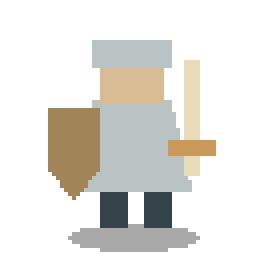
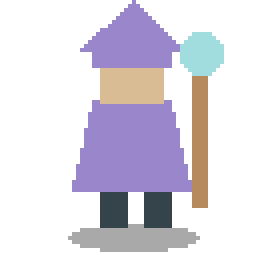
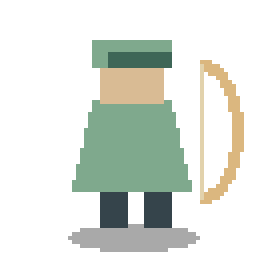

In [8]:
# ไม่ใช้ input() จึง Run all จบได้โดยไม่ค้างรอคำตอบ
notebook_game = NotebookGame()
display(notebook_game.container)

## 8. ทดสอบปุ่มและการวาดหน้าจอ
ทดสอบ callback ของปุ่มจริงด้วย `.click()` และตรวจสถานะหลังคำสั่ง พร้อมตรวจหน้า camp / victory / defeat และปุ่มจบเกม โดยใช้ตัวเกมทดสอบแยกจากส่วนเล่นด้านบน


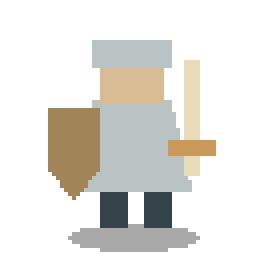
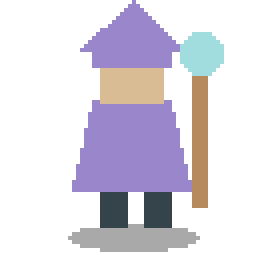
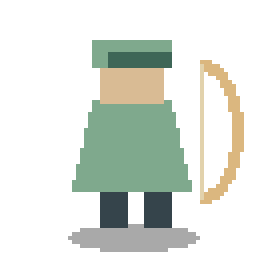

PASS: เลือกอาชีพ → เส้นทาง → ต่อสู้ → กองไฟ → ชนะ/แพ้ → จบเกม → เริ่มใหม่


In [9]:
test_ui = NotebookGame()
test_ui.actions.children[0].click()  # เลือกอัศวิน
assert test_ui.game.mode == 'route'
test_ui.actions.children[0].click()  # เส้นทางลำธาร
assert test_ui.game.mode == 'battle'
hp_before = test_ui.game.enemy['hp']
test_ui.actions.children[0].click()  # โจมตี
assert test_ui.game.enemy['hp'] < hp_before
for mode in ('camp', 'victory', 'defeat'):
    test_ui.game.mode = mode
    test_ui.draw()
test_ui.stop()
assert test_ui.stopped and len(test_ui.actions.children) == 1
test_ui.choose_class()
assert test_ui.game is None
print('PASS: เลือกอาชีพ → เส้นทาง → ต่อสู้ → กองไฟ → ชนะ/แพ้ → จบเกม → เริ่มใหม่')
# ไม่ปิด comm ของ widget ระหว่างรัน kernel; ตัวทดสอบไม่ถูก display ในหน้าเล่น


## 9. ขอบเขตการตรวจและการส่ง
- สมุดบันทึกฉบับนี้มี Code cells จริงและบันทึก outputs หลังรันผ่าน IPython/Jupyter kernel แบบ in-process ในสภาพแวดล้อมจัดทำไฟล์ (ระบบนี้บล็อก socket ของ kernel แบบแยกโปรเซส)
- รันการทดสอบ 2 กรณีและจำลองครบเกม 30 รอบ รวมถึง callback ปุ่มของ widget
- **ไม่ได้เปิดคลิกในบัญชี Google Colab ของผู้ใช้จริง** การแสดง widget/animation อาจต่างกันตาม frontend
- ถ้าหน้า GitHub แสดงปุ่มไม่ได้ ให้ดาวน์โหลดมาเปิดใน Jupyter/Colab และ Run all
- ภาพทดสอบในข้อ 5 เป็น outputs ที่สร้างจากค่าคำนวณจริง ไม่ใช่ภาพหน้าจอจากเครื่องผู้ใช้
- ก่อนส่งให้ทดลองเล่นเอง อธิบาย Conditions, Loops และ Functions ได้ และแนบวิดีโอกับหลักฐาน AI ตามโจทย์

## การใช้ AI
ใช้ ChatGPT ช่วยออกแบบ พัฒนาเกม แก้รูปแบบ notebook ให้รันได้ และเขียนการทดสอบ หลักฐานบทสนทนาอยู่ในโฟลเดอร์ 04_AI_Evidence และควรแนบแชตต้นฉบับเพื่อให้ตรวจย้อนกลับได้